In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats

#random.seed(42)
#np.random.seed(42)

# Principe

- On veut que la sortie $z(t)= \sum z_i R(x_i(t))$ ressemble à $f(t)$ en apprenant les $z_i$.
  $$\dfrac{dx_i}{dt} = -x_i - g \dfrac{1}{n} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + b_i z(t) + I_i$$.
- On utilise $ReLU$ comme taux de décharge, $b$ constant, $w_{i,j} \sim \mathcal{N} \left(0,\dfrac{1}{N^2} \right)$ en gardant uniquement les valeurs négatives, I avec la même valeur pour tous les neurones et $f(t) = sin(\dfrac t 2)$ comme fonction cible. 

On veut minimiser :
$$ \dfrac{1}{T} \int_{0}^{T} (z(t) - f(t))^2 dt) + \dfrac{\rho}{2} \sum z_i^2$$
$$ \iff \dfrac{1}{T} \int_{0}^{T} (z(t) - f(t))^2 dt) + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$
$$ \iff \dfrac{1}{T} \int_{0}^{T} \sum_{i,j} z_i z_j R(x_i (t)) R(x_j (t)) - 2 \sum z_j R(x_j(t)) f(t) + f^2 (t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z $$
$$\iff \dfrac{1}{T} \sum_{i,j} z_i z_j \int_{0}^{T} \langle R(x_i(t)) R(x_j (t)) \rangle - 2 \sum z_j \dfrac{1}{T}  \int_{0}^{T}R(x_ j(t)) f(t) + \dfrac{1}{T} \int_{0}^{T} f^2(t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$

En utilisant le fait que $ \displaystyle \sum_{i} a_i b_i = \langle b \rangle \displaystyle \sum_{i} a_i + \displaystyle \sum_{i} a_i ( b_i - \langle b \rangle)$ et en faisant l'approximation $ \displaystyle \sum_{i} a_i b_i = \langle b \rangle \displaystyle \sum_{i} a_i$ 

On pose : 
$$ c_{i,j} = \dfrac{1}{T}  \int_{0}^{T} \langle R(x_i(t))R(x_j(t)) \rangle = \langle R(x_i(t)) R(x_j(t)) \rangle $$
$$ f_i = \dfrac{1}{T} \int_{0}^{T} R(x_i(t)) f(t)dt $$

Donc on a :

$$Z^TCZ - 2 F^T Z + \dfrac{1}{T} \int_{0}^{T} f^2(t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$

La dérivée par rapport à $Z$ vaut : 

$$ 2CZ - 2F + \rho Z$$

On cherche le minimum de la fonction de coût donc quand :

$$ 2CZ - 2F + \rho Z = 0$$
$$ \iff F = (C + \dfrac {\rho}{2} \mathbb{I}) Z$$
$$ Z = (C + \dfrac {\rho}{2} \mathbb{I})^{-1} F$$

-------
-  Dans un premier temps, pour trouver les $x_i$, on suppose que la procédure marche et on pose :
  $$\dfrac{dx_i}{dt} = -x_i - g \dfrac{1}{n} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + b_i f(t) + I_i$$

- Dans un second temps, on calcule $Z$ avec les $x_i$ trouvés

- Puis on regarde si $Z$ suit bien le motif voulu

# Simulation

## $1$) Calculer les $x_i$

In [2]:
"""
# 2 fréquences :
def f(t):
    return (0.2 * np.sin(np.pi * t/ 5) + 0.3 * np.sin(np.pi * t/ 10))
"""

#commencer par sin :
def f(t):
    return np.sin(np.pi * t/ 5)


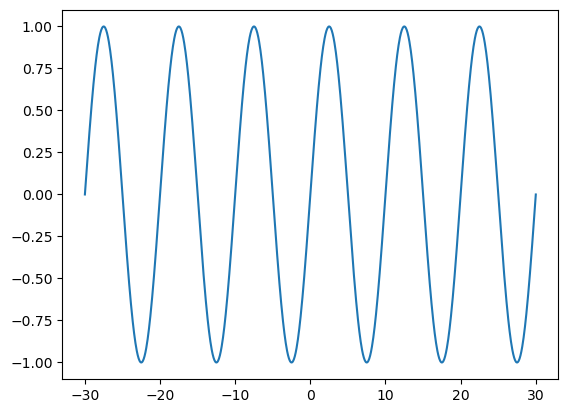

In [3]:
t_test = np.linspace(-30, 30, 1000)
Itv = [f(i) for i in t_test]
plt.plot(t_test, Itv)
plt.show()

In [4]:
n = 1000

In [5]:
def I(n):
    return np.array([random.uniform(0,1) for i in range (n)])

In [6]:
def exemple_X(n):
    X = [random.uniform(-0.5,0.5) for i in range(n)]
    X = np.array(X)
    return X

In [7]:
"""
def W_inhib(n):
    W = []
    w = []
    i=0
    graine = random.Random(42)
    for j in range(n):
        while i<n :
            x = graine.gauss(0,1/n)
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W
"""

def W_pm(n):
    graine = random.Random(42)
    W = [[graine.gauss(0,1/np.sqrt(n)) for j in range (n)] for i in range (n)]
    W = np.array(W)
    return W


In [8]:
"""
def R(X) :
    return np.maximum(X,0)
"""
def R(X) :
    return np.tanh(X)



In [9]:
def B(n) :
    graine = random.Random(42)
    B = [graine.uniform(-0.5,0.5) for i in range(n)]
    B = np.array(B)
    return B

In [10]:
g = 1.2
t_0 = 0
W = W_pm(n) 
B_n = B(n)
X_0 = exemple_X(n)
h = 0.01
T = 100
I_n = I(n)

In [11]:
def deriv_X(X,g,W,B_n,t,I_n) :
    return -X+g* ( W @ R(X)) + B_n * f(t) + I_n

In [12]:
def Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n):
    Images_Euler = [X_0]
    Atcd_Euler = [t_0]
    X = X_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * deriv_X(X,g,W,B_n,t,I_n) + X  
        t += h
        Images_Euler.append(X)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [13]:
def graph_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler])
    plt.show()

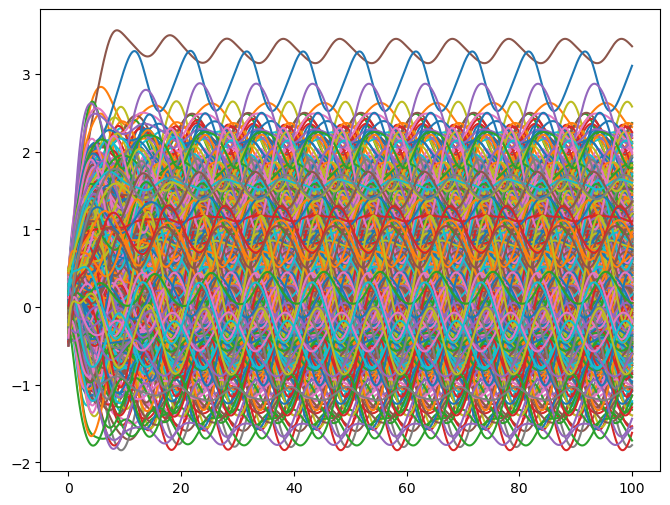

In [14]:
graph_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n)

## $2$) Calculer les $z_i$

In [15]:
Atcd_Euler,Images_Euler = Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n)

On ne veut pas prendre en compte la phase transitoire donc on ne prend pas les valeurs initiales pour calculer $C$ et $F$

In [16]:
t_stable = 10

In [17]:
def C(Images_Euler, h, t_stable):
    X = np.array(Images_Euler)
    i_depart = int(t_stable / h)

    X_stable = X[i_depart:]
    R_X = R(X_stable)

    C= (np.transpose(R_X) @ R_X) / len(R_X)

    return C 

In [18]:
def F_rectangle(Images_Euler,T,h,t_stable):
    S = []
    i_depart = int(t_stable / h)
    for j in range (len(Images_Euler[0])):
        s = 0
        t = t_stable
        for i in range (i_depart, len(Images_Euler)):
            r = h * f(t) * R(Images_Euler[i][j])
            t += h 
            s += r
        S.append(s/(T - t_stable))
    return S

In [19]:
rho = 10**(-4)
C_n = C(Images_Euler,h,t_stable)
F = F_rectangle(Images_Euler,T,h,t_stable)

In [20]:
def z(C_n,F,rho,n):
    return np.linalg.inv(C_n + rho / 2 * np.eye(n)) @ F

In [21]:
z(C_n,F,rho,n)

array([ 1.05699222e-02, -1.70117573e-02, -6.73189920e-03, -1.62004194e-02,
       -2.18831551e-03,  1.06824079e-02,  1.40467845e-02, -2.91384498e-03,
       -7.03176782e-03, -9.36402923e-03, -1.18822522e-02,  4.04875338e-03,
       -8.05041764e-04, -5.39199426e-03,  2.94472351e-03, -5.21920452e-03,
       -7.58143885e-04,  2.72069751e-03,  8.97507204e-03, -1.11525546e-02,
        5.63473872e-03,  2.49203052e-03, -4.74343443e-03, -2.04752476e-03,
        2.59397671e-03,  5.42925166e-04, -1.29333308e-02,  1.54414189e-03,
        3.33142348e-03,  5.81899476e-03,  8.94859502e-03,  3.09600835e-03,
       -1.84248544e-03,  9.85879258e-03, -2.63831575e-03, -6.11157614e-03,
        9.42134500e-03,  3.26880856e-04,  4.17529046e-03, -6.80299548e-03,
        5.82501373e-04, -1.94754718e-03, -3.42063621e-03, -1.98255297e-03,
       -2.24389853e-03, -6.25959704e-03,  7.70602265e-04,  6.32061470e-04,
       -3.38317622e-03, -1.05067380e-03,  1.60470392e-03,  9.72197082e-04,
       -7.19907637e-03,  

In [22]:
z_n = z(C_n,F,rho,n)

In [23]:
def Z(z_n,X):
    return z_n @ R(X)

In [24]:
def graph_sortie_forcé(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,z_n):
    z_sortie = [Z(z_n, X) for X in Images_Euler]
    attente = [f(t) for t in Atcd_Euler]
    
    plt.figure(figsize=(8, 5))
    plt.plot(Atcd_Euler, attente, label="f(t)")
    plt.plot(Atcd_Euler, z_sortie, label="z(t)")
    plt.legend()
    plt.show()

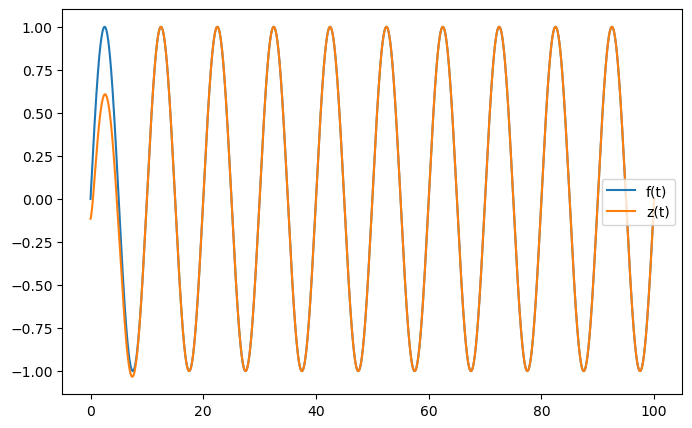

In [25]:
graph_sortie_forcé(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,z_n)

## $3$) Regarder si $z$ correspond à $f(t)$

In [26]:
def deriv_X_ac_Z(X,g,W,B_n,z_n,I_n) :
    return -X+g* ( W @ R(X)) + B_n * Z(z_n,X) + I_n

In [27]:
def Euler_O1_2(deriv_X_ac_Z,t_0,h,T,g,W,B_n,z_n,I_n):
    Images_Euler_2 = [Images_Euler[-1]]
    Atcd_Euler_2 = [t_0]
    X = Images_Euler[-1]
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * deriv_X_ac_Z(X,g,W,B_n,z_n,I_n) + X  
        t += h
        Images_Euler_2.append(X)
        Atcd_Euler_2.append(t)
    return Atcd_Euler_2,np.array(Images_Euler_2)

In [28]:
Atcd_Euler_2,Images_Euler_2 = Euler_O1_2(deriv_X_ac_Z,t_0,h,T,g,W,B_n,z_n,I_n)

In [29]:
def graph_O1_2(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n):
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler_2,[X[i] for X in Images_Euler_2])
    plt.show()

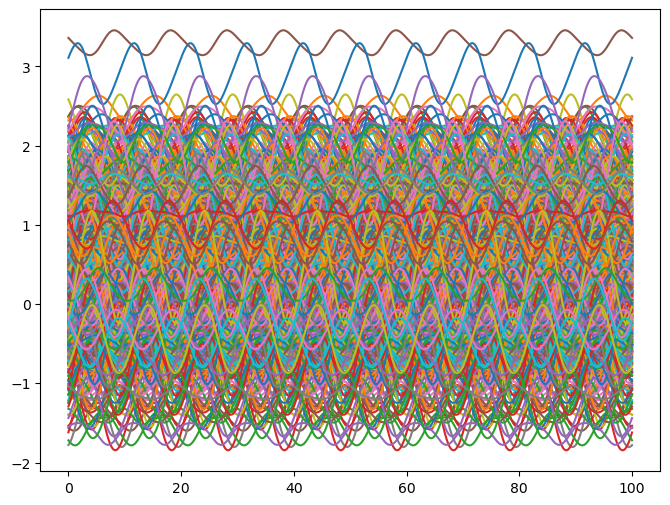

In [30]:
graph_O1_2(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n)

In [31]:
def graph_sortie(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n):
    t = np.array(Atcd_Euler_2) + T
    z_sortie = [Z(z_n, X) for X in Images_Euler_2]
    attente = [f(i) for i in t]
    
    plt.figure(figsize=(8, 5))
    plt.plot(t, attente, label="f(t)",alpha=0.5)
    plt.plot(t, z_sortie, label="z(t)",alpha=0.5)
    plt.legend()
    plt.show()


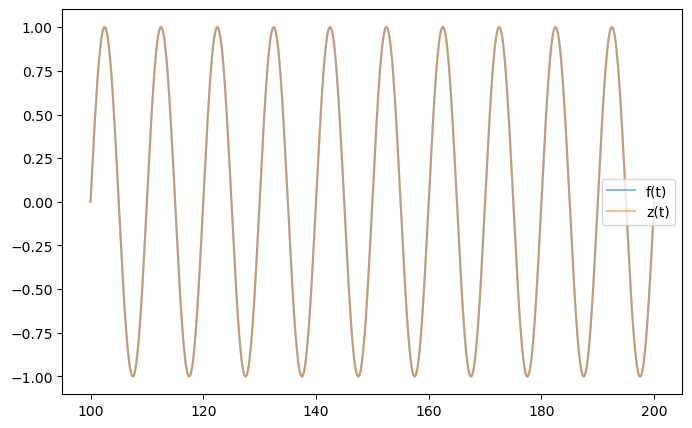

In [32]:
graph_sortie(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n)

## Valeurs propres

### Avec une moyenne

On a : $$ \dfrac{d \delta x_i}{dt} = - \delta x_i + g\sum_{j=1}^{n}( w_{i,j} R'(x_j^*)\delta x_j) + b_i \sum_{j} z_j R'(x_j^*)\delta x_j (t)$$
Donc : $$ \dfrac{d \delta X}{dt} = - \delta X + gWD\delta X + BZ^TD\delta X$$
$$ \iff \dfrac{d \delta X}{dt} = (-I + gWD + BZ^TD)\delta X$$
avec $D$ la matrice diagonale où les coefficients diagonaux valent $1$ si $x_j^*>0$ et $0$ sinon (si $R$ est la fonction $ReLU$)

En posant $M = -I + gWD + BZ^TD$, on a donc :
$$ \dfrac{d \delta X}{dt} = M \delta X $$


In [33]:
#moy
def D(Images_Euler_2,h):    
    X_moy = []
    for j in range (len(Images_Euler_2[0])):
        l=[]
        for i in range (int(-20 / h),0):
            l.append(1-R(Images_Euler_2[i][j])**2)
        X_moy.append(np.mean(l))
    m_diag = np.diag(X_moy)
    return m_diag     


In [34]:
D_n_moy = D(Images_Euler_2,h)

In [35]:

def M(D_n_moy,W,g,B_n,z_n,n):
    return - np.eye(n) + g * W @ D_n_moy + np.outer(B_n, z_n) @ D_n_moy

In [36]:
M_n = M(D_n_moy,W,g,B_n,z_n,n)

In [37]:
def valeurs_propres(M_n):
    V = np.linalg.eigvals(M_n)
    return V

In [38]:
V = valeurs_propres(M_n)

In [39]:
np.linalg.inv(np.eye(n) - g * W @ D_n_moy - np.outer(B_n, z_n) @ D_n_moy) @ I_n

array([ 3.61139934e-01, -3.94199292e-01, -2.48274896e-01, -8.83420095e-02,
        2.11515477e+00,  7.05238904e-01,  5.49221253e-01,  3.74231151e-01,
       -2.73662638e-01,  8.98342227e-02,  4.23408765e-01,  5.88674260e-01,
        1.70011797e+00, -2.12115721e-01,  7.56179676e-01,  4.81324357e-01,
        6.89298520e-01,  1.93535033e+00,  1.28636923e+00, -1.13729054e-01,
        5.60693374e-01,  1.63516576e+00,  1.17302612e+00,  7.58743287e-01,
        9.33276614e-01,  2.68746542e-01, -1.75741290e-01,  2.45840923e-01,
        1.77316740e+00,  1.24603402e+00,  1.06321921e+00,  4.79309625e-01,
        6.42788982e-01, -4.59913746e-01,  1.62891975e-01, -6.30145670e-02,
       -2.97745924e-01,  1.47494008e+00,  5.24346812e-01,  3.13890370e-01,
        2.61658360e-01,  1.36504963e+00,  1.80512015e-01, -7.89520838e-01,
        1.83465822e-01,  3.16419123e-01, -5.19958467e-01,  8.97492975e-01,
        1.47590568e+00,  1.85273496e+00,  9.83446564e-01,  9.71327313e-01,
        5.81581034e-01,  

In [40]:
def graphique_eigvals_W(V,n):
    Atcd,Images = V.real,V.imag
    plt.figure(figsize =(8,8))
    plt.grid()
    plt.scatter(V.real,V.imag, label="Valeurs propres de M")
    plt.xlim(-2, 2)
    plt.ylim(-2,2)
    plt.axhline(0, color="black")
    plt.axvline(0, color="black")
    plt.xlabel("partie réelle")
    plt.ylabel("partie imaginaire")
    plt.legend()
    plt.show()

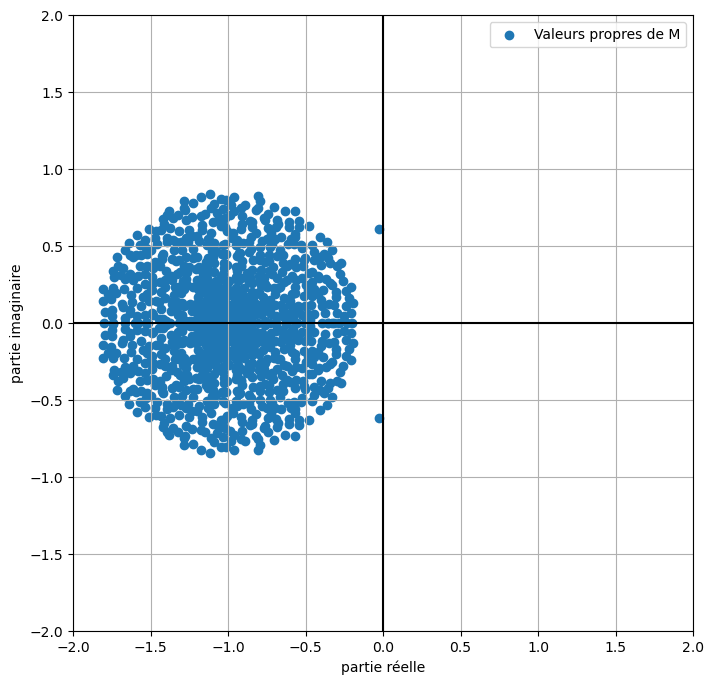

In [41]:
graphique_eigvals_W(V,n)

Spectre du modèle sans $b_iz(t)$ : 

In [42]:

def M_bis(D_n_moy,W,g,n):
    return - np.eye(n) + g * W @ D_n_moy

In [43]:
M_b = M_bis(D_n_moy,W,g,n)

In [44]:
V_b = valeurs_propres(M_b)

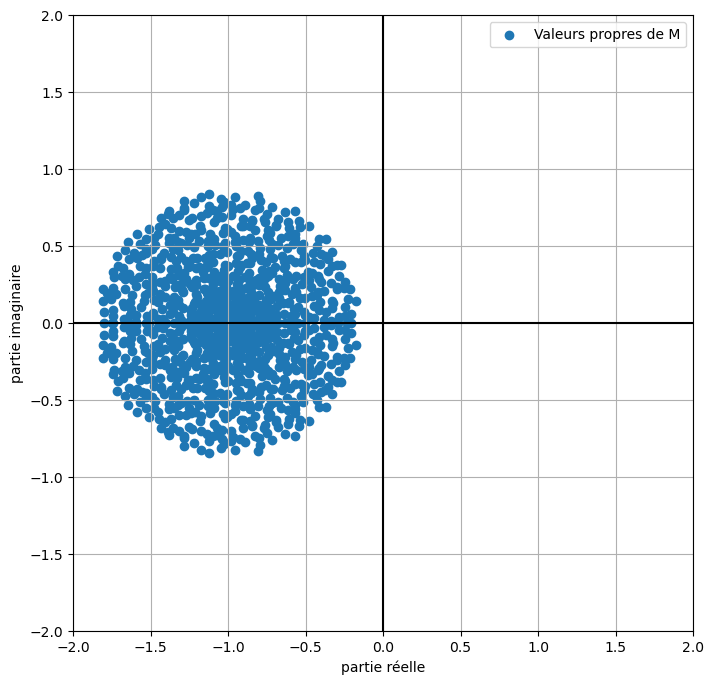

In [45]:
graphique_eigvals_W(V_b,n)

### Avec la méthode de Newton

In [46]:
def deriv_R (X):
    return 1 - np.tanh(X)**2

In [47]:
def eq_eqb(X, W, g, B_n, z_n, I_n) :
    return -X + g * (W @ R(X)) + B_n * (z_n @ R(X)) + I_n

Prendre la moyenne des derniers $x_i$ comme point de départ pour la méthode de Newton :

In [48]:
X_ini = np.mean(Images_Euler_2[int(-20 / h):, :],axis=0)

In [49]:
E = np.array([1e-8 for i in range (n)])

In [50]:
max_iter = 100

In [51]:
def newton(eq_eqb,M_n,X_ini,E):
    delta = np.array([1 for i in range (n)])
    k = 0
    while np.any(delta > E) and k < max_iter :
        D_n = np.diag (deriv_R (X_ini))
        X = - np.linalg.inv(M(D_n,W,g,B_n,z_n,n) ) @ eq_eqb(X_ini, W, g, B_n, z_n, I_n) + X_ini
        delta = np.abs(X - X_ini)
        X_ini = X
        k+=1
        
    return X , delta

$M$ après la méthode de Newton :

In [52]:
X,delta = newton(eq_eqb,M_n,X_ini,E)
D_n = np.diag (deriv_R (X))
M_n_newton = M(D_n,W,g,B_n,z_n,n)


In [53]:
np.linalg.inv(np.eye(n) - g * W @ D_n - np.outer(B_n, z_n) @ D_n) @ I_n

array([ 2.84654373e-01, -4.31930050e-01, -3.09201875e-01, -6.13943813e-02,
        2.19713975e+00,  5.64706761e-01,  7.78039780e-01,  4.21726582e-01,
       -4.88206371e-01,  2.34296598e-01,  3.06669843e-01,  5.86973012e-01,
        1.91275776e+00, -3.22697107e-01,  9.11415897e-01,  4.59511650e-01,
        5.05841154e-01,  1.94821837e+00,  1.33528823e+00, -7.44159429e-02,
        4.70698022e-01,  1.77848642e+00,  1.20011553e+00,  5.19054738e-01,
        8.96959893e-01,  2.25664626e-01, -1.95906824e-01,  1.72074242e-01,
        1.80826095e+00,  1.21674222e+00,  1.15306973e+00,  4.76314648e-01,
        5.58808304e-01, -4.66055752e-01,  1.70886724e-01, -1.80514926e-01,
       -4.31676663e-01,  1.48776118e+00,  3.38573598e-01,  4.51711490e-01,
        2.89395113e-01,  1.44182496e+00,  1.84042715e-01, -8.05227866e-01,
        2.33277675e-01,  1.91091146e-01, -5.21046644e-01,  8.84449424e-01,
        1.65275671e+00,  2.03949031e+00,  9.15767521e-01,  1.08854285e+00,
        5.42919931e-01,  

In [54]:
V_newton = valeurs_propres(M_n_newton)

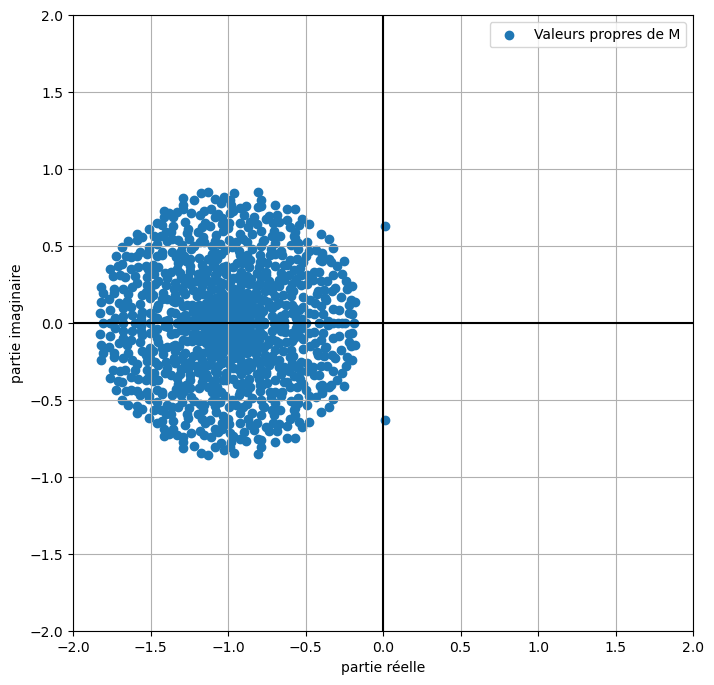

In [55]:
graphique_eigvals_W(V_newton,n)

Spectre du modèle sans $b_iz(t)$ : 

In [56]:
M_b_newton = M_bis(D_n, W,g,n)

In [57]:
V_b_newton = valeurs_propres(M_b_newton)

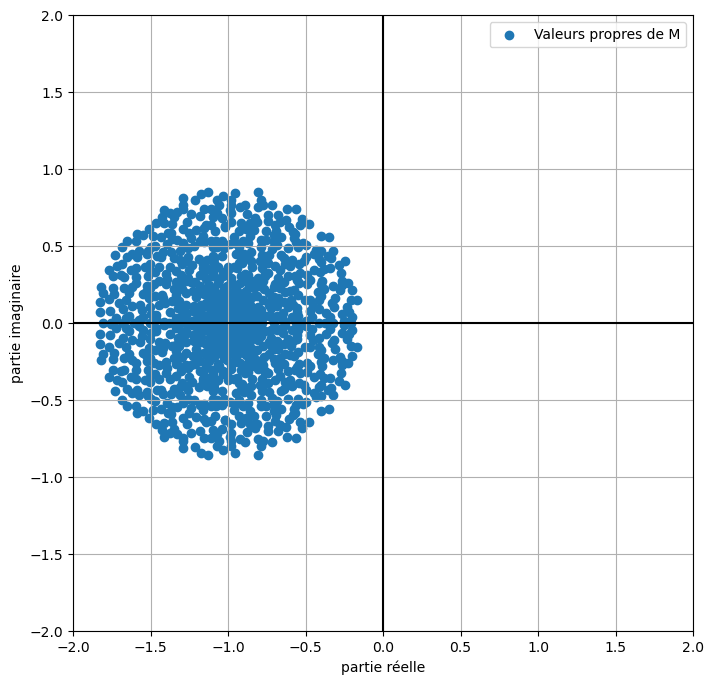

In [58]:
graphique_eigvals_W(V_b_newton,n)